In [2]:
from manim import *

video_scene = " -v WARNING --disable_caching  clement_desormes_Scene"
image_scene = f" -v WARNING --disable_caching -r {2*427},{2*240}  -s  clement_desormes_Scene"

In [74]:
class PressureBox(Mobject):
	def __init__(self, box_center = np.array([-3, -0.5, 0]), box_width = 3, box_height = 4, box_stroke_width = 4, **kwargs):
		super().__init__(**kwargs)

		# parameters
		self.valve_width = 0.25
		self.pump_width = 0.5


		# box corners
		box_corner_TL = box_center + box_width/2*LEFT + box_height/2*UP
		box_corner_TR = box_center + box_width/2*RIGHT + box_height/2*UP
		box_corner_DL = box_center + box_width/2*LEFT + box_height/2*DOWN
		box_corner_DR = box_center + box_width/2*RIGHT + box_height/2*DOWN

		# valve corners
		valve_exit_left = box_corner_TL + box_width/2*RIGHT + self.valve_width/2*LEFT
		valve_exit_right = box_corner_TL + box_width/2*RIGHT + self.valve_width/2*LEFT + self.valve_width*RIGHT
		self.valve_left = valve_exit_left + 2*self.valve_width*UP
		self.valve_right = valve_exit_right + 2*self.valve_width*UP
		
		# pump corners
		pump_exit_up = box_corner_TL + (box_height/2-self.pump_width)*DOWN
		pump_exit_down = box_corner_TL + (box_height/2-self.pump_width)*DOWN + self.pump_width*DOWN
		pump_exit_up_left = pump_exit_up + self.pump_width*LEFT
		pump_exit_down_left = pump_exit_down + self.pump_width*LEFT
		pump_up_right = pump_exit_up_left + self.pump_width/2*UP
		pump_down_right = pump_exit_down_left + self.pump_width/2*DOWN
		self.pump_up = pump_up_right + self.pump_width*LEFT
		self.pump_down = pump_down_right + self.pump_width*LEFT

		# manometre corners

		pressure_box_polygon_position_list = [
			self.pump_up, pump_up_right, pump_exit_up_left, pump_exit_up, 
			box_corner_TL,
			valve_exit_left, self.valve_left, self.valve_right, valve_exit_right,
			box_corner_TR,
			box_corner_DR,
			box_corner_DL,
			pump_exit_down, pump_exit_down_left, pump_down_right, self.pump_down
			]
		self.pressure_box_polygon = Polygon(*pressure_box_polygon_position_list, stroke_color = BLACK, stroke_width = box_stroke_width, fill_color = BLUE, fill_opacity = 0.5, stroke_opacity = 0)
		self.add(self.pressure_box_polygon)



		# pump
		# def get_piston(self, t, wave_params):
		# 	# create piston frame
		# 	piston_width = 1
		# 	piston_top_width = 0.2
		# 	line_top = Line(start = self.top_left, end = self.top_left - piston_width*RIGHT, stroke_width = 2, color = MAIN_COLOR)
		# 	line_left = Line(start = self.top_left - RIGHT, end = self.bottom_left - RIGHT, stroke_width = 2, color = MAIN_COLOR)
		# 	line_bottom = Line(start = self.bottom_left, end = self.bottom_left - piston_width*RIGHT, stroke_width = 2, color = MAIN_COLOR)
		# 	piston_frame = VGroup(line_top, line_left, line_bottom)
		# 	# get amplitude for given t at x = 0
		# 	amplitude_at_zero = get_wave_in(t, wave_params)(0)
		# 	piston_shift = amplitude_at_zero / 4 - 0.25
		# 	# create top of the piston
		# 	piston_top = Polygon(
		# 		self.top_left + piston_shift*RIGHT, 
		# 		self.bottom_left + piston_shift*RIGHT, 
		# 		self.bottom_left - piston_top_width*RIGHT + piston_shift*RIGHT, 
		# 		self.top_left-piston_top_width*RIGHT + piston_shift*RIGHT, 
		# 		stroke_width = 2, color = MAIN_COLOR, fill_opacity = 0.75
		# 	)
		# 	# create the bottom of the piston
		# 	piston_bottom_width = 0.1
		# 	piston_bottom_right_center = (self.top_left+self.bottom_left) / 2 + piston_shift*RIGHT
		# 	piston_bottom_left_center = (self.top_left+self.bottom_left) / 2 - piston_width*RIGHT
		# 	piston_bottom = Polygon(
		# 		piston_bottom_right_center - piston_top_width*RIGHT + piston_bottom_width/2 * UP,
		# 		piston_bottom_right_center - piston_top_width*RIGHT - piston_bottom_width/2 * UP,
		# 		piston_bottom_left_center - piston_bottom_width/2 * UP,
		# 		piston_bottom_left_center + piston_bottom_width/2 * UP,  
		# 		stroke_width = 2, color = MAIN_COLOR, fill_opacity = 1      
        # )
        # piston = VGroup(piston_frame, piston_top, piston_bottom)
        # return piston


		# valve


		# manometre


class PVDiagram(Mobject):
	def __init__(self, box_center = np.array([3, -0.5, 0]), ax_width = 3, ax_height = 4, **kwargs):
		super().__init__(**kwargs)

Manim Community v0.22.1

[11/13/26 13:13:15] WARNING  clement_desormes_Scene has no play calls. Automatic video output has    ]8;id=7073525;file:///home/carlo/Desktop/physics-education-animations/animations_code/.venv_per/lib/python3.14/site-packages/manim/manager.py\manager.py]8;;\:]8;id=7073526;file:///home/carlo/Desktop/physics-education-animations/animations_code/.venv_per/lib/python3.14/site-packages/manim/manager.py#219\219]8;;\
                             been saved as a PNG instead.                                                          

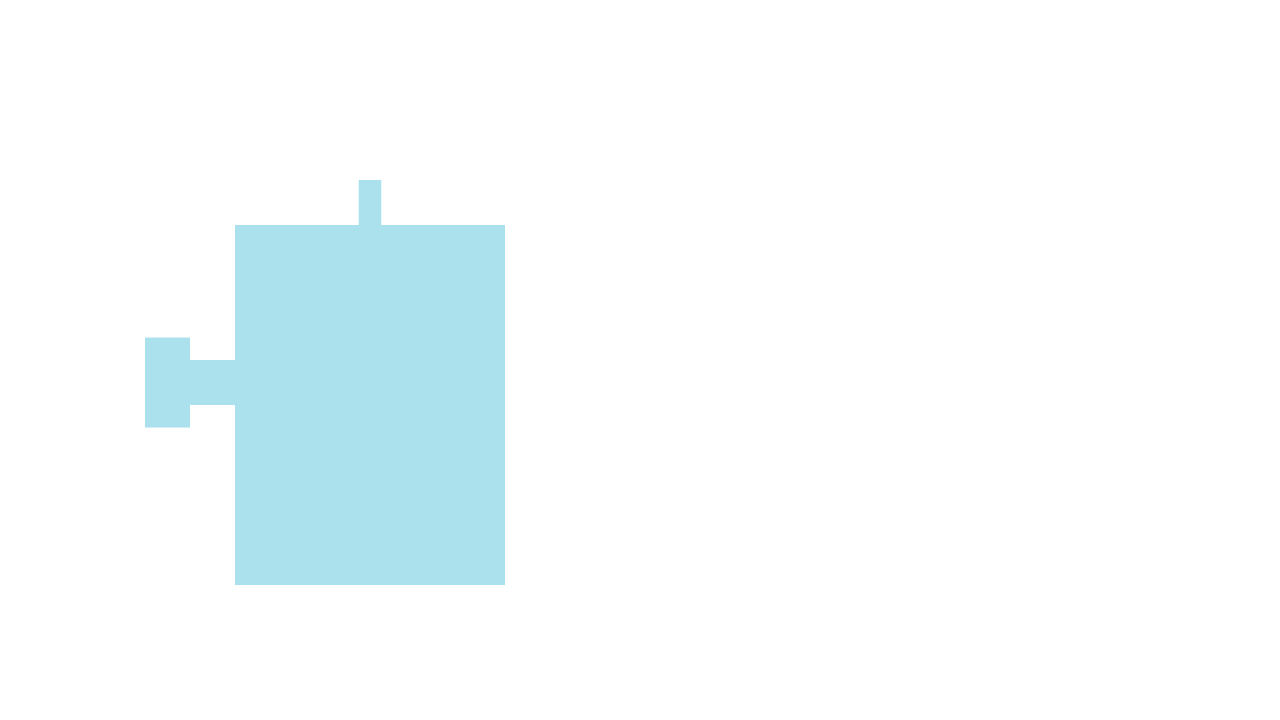

In [75]:
%%manim -qm --fps 60 $video_scene


class clement_desormes_Scene(Scene):
	def construct(self):
		self.camera.background_color = WHITE

		CVC = Text('CVC', font_size = 12, weight = BOLD, color = WHITE, font = 'Latin Modern Sans').align_on_border(RIGHT + DOWN, buff = 0.2)
		self.add(CVC)

		pressure_box = PressureBox()
		self.add(pressure_box)

		# print(pressure_box.pressure_box_polygon.Polygram)